In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import json, pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow import keras
from keras.utils import set_random_seed
from keras.models import Model
from keras.optimizers import Adam
from keras.layers import Conv1D, Dropout, BatchNormalization, Activation, add, Bidirectional, LSTM, GRU, Input, Dense
# Flatten, MaxPool1D

In [3]:
DATA_JSON_PATH = ".\\Features\\data35_features.json"
PICKLE_PATH = "/content/drive/MyDrive/AUT/Project/Features/DATA_NFFT2048_HOP1024.pkl"

In [4]:
def load_data():
    with open(PICKLE_PATH, "rb") as input:
        DATA = pickle.load(input)

    X = np.array(DATA["mfccs"], dtype=np.float32)
    y1 = np.array(DATA["labels"]["instrument"], dtype=np.int8)
    y2 = np.array(DATA["labels"]["scale"], dtype=np.int8)

    return X, y1, y2

In [5]:
def tmp_load_data(num_data=9000):

    X = np.random.randn(num_data, 431, 45).astype(np.float64)
    y1 = np.random.randint(5, size=num_data, dtype=np.int32)
    y2 = np.random.randint(7, size=num_data, dtype=np.int32)

    return X, y1, y2

In [6]:
def prepare_dataset():
    X, y1, y2 = load_data()

    X_train, X_test, y1_train, y1_test, y2_train, y2_test = \
        train_test_split(X, y1, y2, test_size=0.15, shuffle=True, random_state=0)
    
    X_test, X_val, y1_test, y1_val, y2_test, y2_val = \
        train_test_split(X_test, y1_test, y2_test, test_size=0.5, shuffle=True, random_state=0)
    
    return X_train, X_test, X_val, y1_train, y1_test, y1_val, y2_train, y2_test, y2_val

In [7]:
def Residual_Conv1D(model, num_filters=512):

    def conv1D(model, dropout):
        model = Conv1D(filters=num_filters, kernel_size=5, padding='same')(model)
        model = Dropout(dropout)(model)
        model = BatchNormalization()(model)
        model = Activation('relu')(model)
        return model

    model_in = model

    model = conv1D(model, dropout=0.1)
    model = conv1D(model, dropout=0.2)

    shortcut = Conv1D(filters=num_filters, kernel_size=3, padding='same')(model_in)
    shortcut = BatchNormalization()(shortcut)

    model_out = add([shortcut, model])
    model_out = Activation('relu')(model_out)

    return model_out

In [8]:
def Encoder(model):

    def BiLSTM(model, num_units, return_seq=True):
        model = Bidirectional(LSTM(units=num_units, return_sequences=return_seq))(model)
        model = BatchNormalization()(model)
        return model
    
    model = BiLSTM(model, num_units=256)
    model = BiLSTM(model, num_units=128)
    model = BiLSTM(model, num_units=64)

    return model

In [9]:
def Decoder(model):

    def BiGRU(model, num_units, return_seq=True):
        model = Bidirectional(GRU(units=num_units, return_sequences=return_seq))(model)
        model = BatchNormalization()(model)
        return model
    
    model = BiGRU(model, num_units=32)
    model = BiGRU(model, num_units=64)
    model = BiGRU(model, num_units=128)
    model = BiGRU(model, num_units=256, return_seq=False)

    return model

In [10]:
def FC_Dense(model, unit):
    model = Dense(units=unit, activation='relu', kernel_regularizer=keras.regularizers.l2(0.05))(model)
    model = Dropout(0.5)(model)

    return model

In [11]:
def Output(models):
    y1_output = Dense(units=5, activation='softmax', name='instrument')(models[0])
    y2_output = Dense(units=7, activation='softmax', name='scale')(models[1])

    return (y1_output, y2_output)

In [12]:
def build_model(input_shape) -> Model:

    input = Input(input_shape)
    model = Residual_Conv1D(input)
    model = Encoder(model)
    model = Decoder(model)
    model_1 = FC_Dense(model, unit=16)
    model_2 = FC_Dense(model, unit=24)
    output = Output((model_1, model_2))
    model = Model(inputs=input, outputs=output)

    return model

In [13]:
X_train, X_test, X_val, y1_train, y1_test, y1_val, y2_train, y2_test, y2_val = prepare_dataset()
Y_train = (y1_train, y2_train)
Y_test = (y1_test, y2_test)
Y_val = (y1_val, y2_val)

del y1_train, y1_test, y1_val, y2_train, y2_test, y2_val

In [14]:
set_random_seed(0)
model = build_model(input_shape=(X_train.shape[1], X_train.shape[2]))
# model.summary()

optimizer = Adam(learning_rate=0.001)
model.compile(
    optimizer=optimizer,
    loss={
        'instrument': 'sparse_categorical_crossentropy',
        'scale': 'sparse_categorical_crossentropy'
    },
    metrics={
        'instrument': ['accuracy'],
        'scale': ['accuracy']
    }
)

history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=128,
                    epochs=130)

Epoch 1/130
64/64 [==============================] - 65s 525ms/step - loss: 5.9499 - instrument_loss: 0.9112 - scale_loss: 2.1614 - instrument_accuracy: 0.6571 - scale_accuracy: 0.1879 - val_loss: 4.8444 - val_instrument_loss: 0.9327 - val_scale_loss: 1.9145 - val_instrument_accuracy: 0.6890 - val_scale_accuracy: 0.2176
Epoch 2/130
64/64 [==============================] - 28s 442ms/step - loss: 3.7989 - instrument_loss: 0.5105 - scale_loss: 1.8468 - instrument_accuracy: 0.8020 - scale_accuracy: 0.2568 - val_loss: 3.2732 - val_instrument_loss: 0.4520 - val_scale_loss: 1.8434 - val_instrument_accuracy: 0.8870 - val_scale_accuracy: 0.2497
Epoch 3/130
64/64 [==============================] - 28s 442ms/step - loss: 2.7777 - instrument_loss: 0.3672 - scale_loss: 1.6958 - instrument_accuracy: 0.8585 - scale_accuracy: 0.3267 - val_loss: 2.3368 - val_instrument_loss: 0.2062 - val_scale_loss: 1.6330 - val_instrument_accuracy: 0.9428 - val_scale_accuracy: 0.4073
Epoch 4/130
64/64 [===============

In [15]:
loss, instrument_loss, scale_loss, instrument_accuracy, scale_accuracy = model.evaluate(X_test, Y_test)
print(f"\nTest Results:\n")
print(f"Total Loss: {loss}")
print(f"Instrument Loss: {instrument_loss}")
print(f"Scale Loss: {scale_loss}")
print(f"Instrument Accuracy on Test Set: {instrument_accuracy}")
print(f"Scale Accuracy on Test Set: {scale_accuracy}")

23/23 [==============================] - 3s 114ms/step - loss: 0.4360 - instrument_loss: 0.0185 - scale_loss: 0.3644 - instrument_accuracy: 0.9958 - scale_accuracy: 0.9275

Test Results:

Total Loss: 0.43602460622787476
Instrument Loss: 0.018536103889346123
Scale Loss: 0.3643709123134613
Instrument Accuracy on Test Set: 0.9958158731460571
Scale Accuracy on Test Set: 0.9274755716323853


In [16]:
def plot_history(history):

    def plot_result(metrics, labels, y_label, title, location):
        plt.plot(history.history[metrics[0]], label=labels[0])
        plt.plot(history.history[metrics[1]], label=labels[1])
        plt.title(title)
        plt.xlabel("Epoch")
        plt.ylabel(y_label)
        plt.legend(loc=location)
        # plt.savefig("/content/drive/MyDrive/proj/pic/MFCC_B128_E130_M30/" + title + ".png")
        plt.show()
        print("\n\n")

    # create accuracy sublpot
    plot_result(metrics=("instrument_accuracy", "val_instrument_accuracy"),
                 labels=("Instrument Train Accuracy", "Instrument Test Accuracy"),
                 y_label="Accuracy", title="Instrument Accuracy Evaluation", location="lower right")

    plot_result(metrics=("instrument_loss", "val_instrument_loss"),
                 labels=("Instrument Train Error", "Instrument Test Error"),
                 y_label="Loss", title="Instrument Error Evaluation", location="upper right")
    
    plot_result(metrics=("scale_accuracy", "val_scale_accuracy"),
                 labels=("Scale Train Accuracy", "Scale Test Accuracy"),
                 y_label="Accuracy", title="Scale Accuracy Evaluation", location="lower right")
    
    plot_result(metrics=("scale_loss", "val_scale_loss"),
                 labels=("Scale Train Error", "Scale Test Error"),
                 y_label="Loss", title="Scale Error Evaluation", location="upper right")

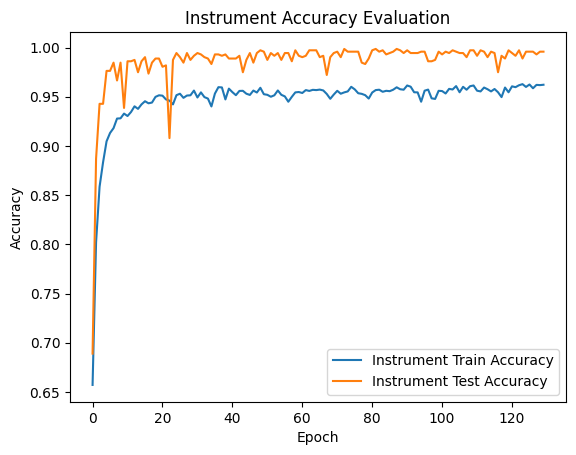

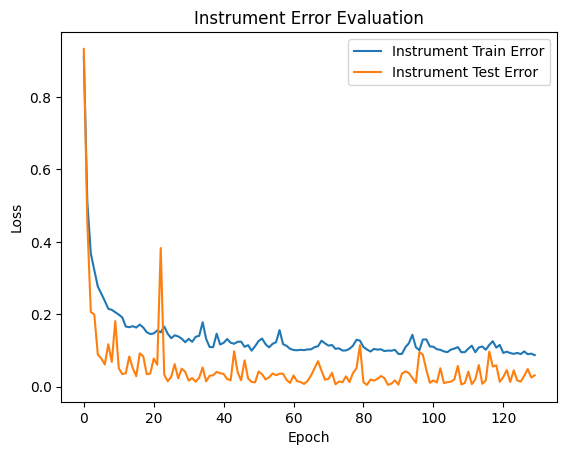

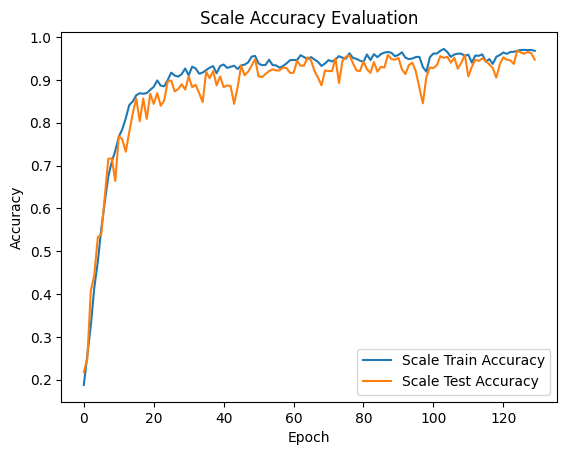

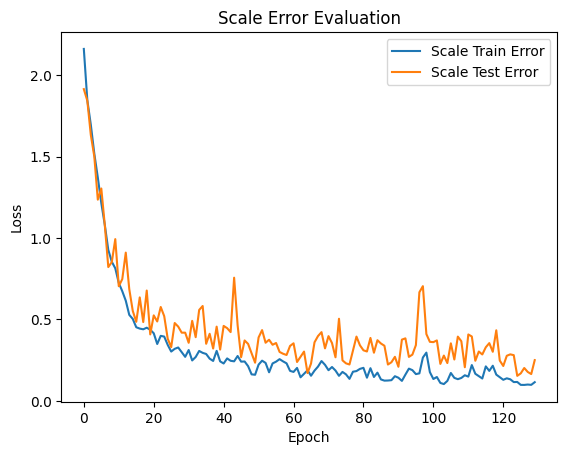

In [17]:
plot_history(history)